In [5]:
import pandas as pd
import os
import matplotlib.pyplot as plt

In [6]:
folder = "data"
print(os.listdir(folder))

['2022-23-player-season-totals.csv', '2023-24-player-season-totals.csv', '2024-25-player-season-totals.csv', '2025-26-player-season-totals.csv', '2026-27-player-season-totals.csv']


In [7]:
seasons = [
    "2022-23",
    "2023-24",
    "2024-25",
    "2025-26",
    "2026-27"
]
all_seasons = []
for season in seasons:
    filename = season + "-player-season-totals.csv"
    filepath = os.path.join(folder, filename)
    data = pd.read_csv(filepath)
    all_seasons.append(data)
    print("Loaded", season, "-", len(data), "records")

nba_players = pd.concat(all_seasons, ignore_index=True)

print("\nNBA Database Created")
print("Total records:", len(nba_players))

Loaded 2022-23 - 539 records
Loaded 2023-24 - 572 records
Loaded 2024-25 - 569 records
Loaded 2025-26 - 582 records
Loaded 2026-27 - 452 records

NBA Database Created
Total records: 2714


In [8]:
nba_players.to_csv("NBA_Master_Database.csv", index=False)
print("Dataspace saved successfully.")

Dataspace saved successfully.


In [9]:
print(nba_players.head(10))
print("\nStatistic Columns:")
print(nba_players.columns.tolist())
print("\nDatabase Size:")
print(nba_players.shape)

    season        player_name team position   age  games_played    minutes  \
0  2022-23      Mikal Bridges  BKN      NaN  26.0            83  2963.1767   
1  2022-23    Anthony Edwards  MIN      NaN  21.0            79  2841.4550   
2  2022-23        Zach LaVine  CHI      NaN  28.0            77  2767.9500   
3  2022-23     Nikola Vučević  CHI      NaN  32.0            82  2746.3550   
4  2022-23      Julius Randle  NYK      NaN  28.0            77  2737.2517   
5  2022-23   Domantas Sabonis  SAC      NaN  27.0            79  2735.5550   
6  2022-23       Jayson Tatum  BOS      NaN  25.0            74  2732.1967   
7  2022-23  Spencer Dinwiddie  BKN      NaN  30.0            79  2725.3350   
8  2022-23        Evan Mobley  CLE      NaN  22.0            79  2715.2617   
9  2022-23    Dejounte Murray  ATL      NaN  26.0            74  2693.3950   

   points  rebounds  assists  ...  points_pg  rebounds_pg  assists_pg  ts_pct  \
0    1671       364      273  ...    20.1325       4.3855   

In [10]:
def player_lookup(player_name):
    matches = nba_players[
        nba_players["player_name"].str.lower() == player_name.lower()]

    if matches.empty:
        print("Player not found.")

    else:
        matches = matches.sort_values("season")

        for index, player in matches.iterrows():
            print("\n")
            print("PLAYER:", player["player_name"])
            print("SEASON:", player["season"])
            print("TEAM:", player["team"])
            print()

            stats = player.drop(["player_name", "season", "team"])
            print(stats.to_string())

In [22]:
player_name = input("Enter an NBA player's name:")
player_lookup(player_name)

Enter an NBA player's name: Anthony Edwards




PLAYER: Anthony Edwards
SEASON: 2022-23
TEAM: MIN

position                     NaN
age                         21.0
games_played                  79
minutes                 2841.455
points                      1946
rebounds                     458
assists                      350
steals                       125
blocks                        58
turnovers                    259
field_goals_made             707
field_goal_attempts         1541
field_goal_pct             0.459
three_point_makes            213
three_point_attempts         578
three_point_pct            0.369
free_throws_made             319
free_throw_attempts          422
free_throw_pct             0.756
points_pg                24.6329
rebounds_pg               5.7975
assists_pg                4.4304
ts_pct                     0.564
effective_fg_pct          0.5279
usage_rate                 0.292
ast_pct                   0.2024
reb_pct                   0.0908
tov_pct                   0.1304
net_rating             

In [27]:
def player_plot(player_name):
    player_data = nba_players[nba_players["player_name"].str.lower() == player_name.lower()]
    if player_data.empty:
        print("Player not found. Try again.")
    elif len(player_data) < 2:
        print("Not enough seasons to preform regression.")
    else:
        player_data = player_data.sort_values("season")
        x = [int(str(season)[:4]) for season in player_data["season"]]
        y = list(player_data["points_pg"])
        x_mean = sum(x) / len(x)
        y_mean = sum(y) / len(y)
        numerator = sum((x[i] - x_mean) * (y[i] - y_mean) for i in range(len(x)))
        denominator = sum((x[i] - x_mean) ** 2 for i in range (len(x)))
        slope = numerator / denominator
        intercept = y_mean - slope * x_mean
        predicted = [intercept + slope * year for year in x]
        sse = sum((y[i] - predicted[i]) ** 2 for i in range(len(y)))
        sst = sum((value - y_mean) ** 2 for value in y)
        if sst != 0:
            r_squared = 1 - (sse / sst)
        else:
            r_squared = 0
        next_season = max(x) + 1
        next_prediction = intercept + slope * next_season
        print("Player:", player_name)
        print("Regression equation: y =", round(intercept, 2), "+", round(slope, 3), "x")
        print("Points per game change per season:", round(slope, 2))
        print("R-squared:", round(r_squared, 3))
        print("Estimayed next season PPG:", round(next_prediction, 2))
        plt.figure(figsize=(10, 5))
        plt.scatter(x, y, label="Actual PPG")
        plt.plot(x, predicted, label="Regression Line")
        plt.scatter(next_season, next_prediction, marker="x", s=100, label="Next Season Estimate")
        plt.title(player_name + " - Scoring Regression")
        plt.xlabel("NBA Season (Starting Year)")
        plt.ylabel("Points Per Game")
        plt.legend()
        plt.grid(True)
        plt.show()
    
    

Enter an NBA player's name:  Anthony Edwards


Player: Anthony Edwards
Regression equation: y = -4040.37 + 2.01 x
Points per game change per season: 2.01
R-squared: 0.918
Estimayed next season PPG: 34.07


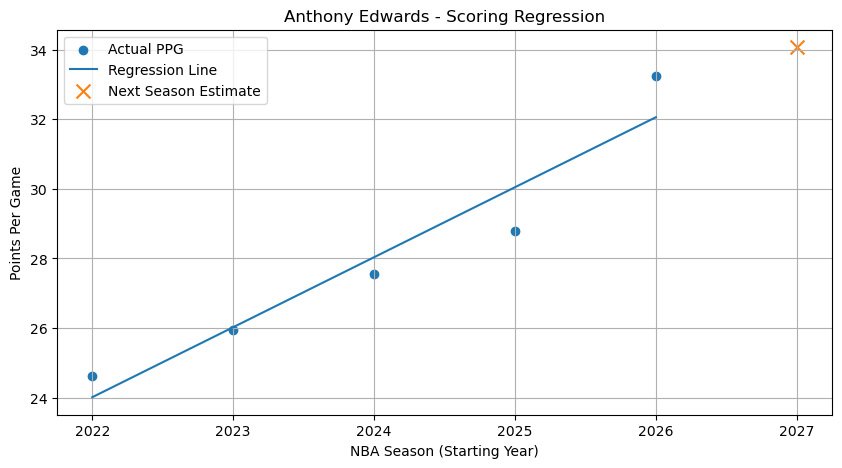

In [28]:
player_name = input("Enter an NBA player's name: ")
player_plot(player_name)